## Exercise 4

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import icemodel
import pandas as pd

In [2]:
x = np.load("coordinates.npy")
h = np.load("surface.npy")
ux = np.load("ux.npy")

In [3]:
print("x:", x.shape)
print("h:", h.shape)
print("ux:", ux.shape)

x: (51,)
h: (51,)
ux: (51,)


In [4]:
print("First x values:", x[:5])
print("First h values:", h[:5])
print("First ux values:", ux[:5])

First x values: [   0. 2000. 4000. 6000. 8000.]
First h values: [819.50290071 813.75798214 807.94927827 802.02597516 795.91405945]
First ux values: [1.09254759 1.10508449 1.11639327 1.13495242 1.16322224]


In [5]:
print(x)

[     0.   2000.   4000.   6000.   8000.  10000.  12000.  14000.  16000.
  18000.  20000.  22000.  24000.  26000.  28000.  30000.  32000.  34000.
  36000.  38000.  40000.  42000.  44000.  46000.  48000.  50000.  52000.
  54000.  56000.  58000.  60000.  62000.  64000.  66000.  68000.  70000.
  72000.  74000.  76000.  78000.  80000.  82000.  84000.  86000.  88000.
  90000.  92000.  94000.  96000.  98000. 100000.]


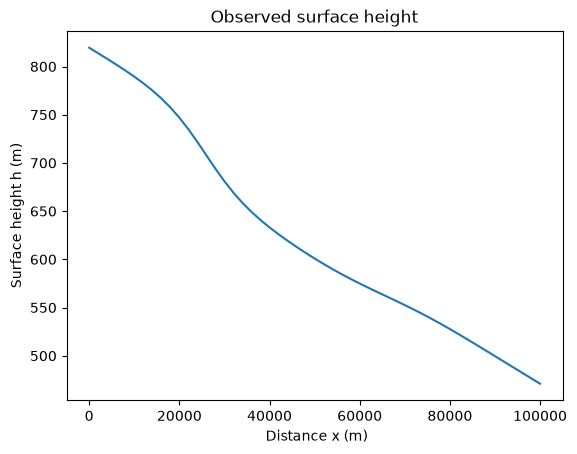

In [6]:
#surface plot
plt.figure()
plt.plot(x, h)
plt.xlabel(" Distance x (m)")
plt.ylabel("Surface height h (m)")
plt.title("Observed surface height")
plt.show()

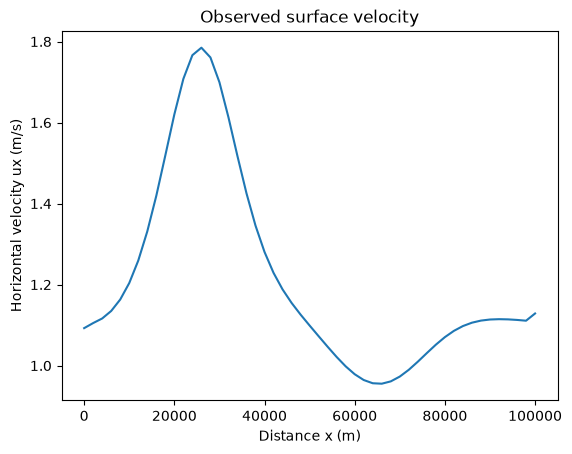

In [7]:
#Velocity Plot
plt.figure()
plt.plot(x, ux)
plt.xlabel("Distance x (m)")
plt.ylabel("Horizontal velocity ux (m/s)")
plt.title("Observed surface velocity")
plt.show()

## Part 1

In [8]:
#Calculate surface gradient dh/dx

dx = x[1] - x[0]

dhdx = np.zeros(len(h))

# Interior points
for i in range(1, len(h) - 1):
    dhdx[i] = (h[i+1] - h[i-1]) / (2*dx)

# Boundary points
heightdiff = h[0] - h[-1]

dhdx[0] = (h[1] - (h[-2] + heightdiff)) / (2*dx)

dhdx[-1] = ((h[1] - heightdiff) - h[-2]) / (2*dx)

In [9]:
print(dhdx)

[-0.00285929 -0.00288841 -0.002933   -0.0030088  -0.00312898 -0.00330986
 -0.00357056 -0.00393115 -0.00440708 -0.00499695 -0.00566194 -0.00630521
 -0.00677712 -0.00693342 -0.00672358 -0.00622759 -0.00559945 -0.00497829
 -0.00444318 -0.00401837 -0.0036964  -0.00345682 -0.00327624 -0.00313283
 -0.00300847 -0.0028901  -0.00277064 -0.00264913 -0.00252973 -0.00241962
 -0.00232679 -0.00225811 -0.00221827 -0.00220942 -0.00223113 -0.00228043
 -0.00235189 -0.00243795 -0.00252972 -0.00261832 -0.00269639 -0.00275932
 -0.00280559 -0.00283632 -0.0028542  -0.00286247 -0.00286413 -0.00286153
 -0.00285637 -0.00284972 -0.00285929]


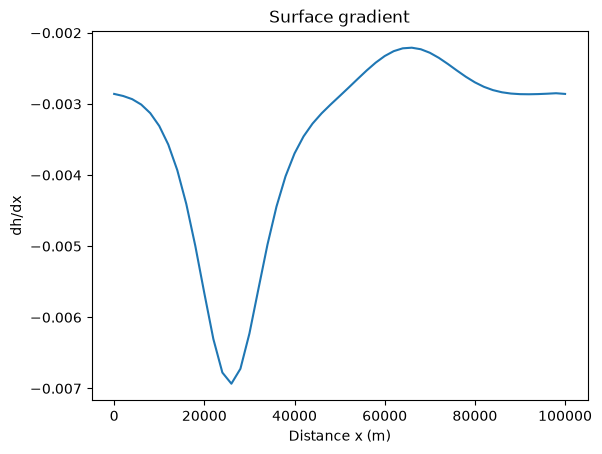

In [10]:
plt.figure()
plt.plot(x, dhdx)
plt.xlabel("Distance x (m)")
plt.ylabel("dh/dx")
plt.title("Surface gradient")
plt.show()

In [11]:
#calculate the ice thickness H using SIA equation 
A = 300
rho = 9.138e-19
grav = 9.7692e15
n = 3

H = (
    ux * (n + 1)
    / (-2 * A * (rho * grav)**n * dhdx**n)
)**(1/(n+1))

In [12]:
print("Minimum ice thickness:", np.min(H))
print("Maximum ice thickness:", np.max(H))

Minimum ice thickness: 473.2956949327889
Maximum ice thickness: 954.5074299592322


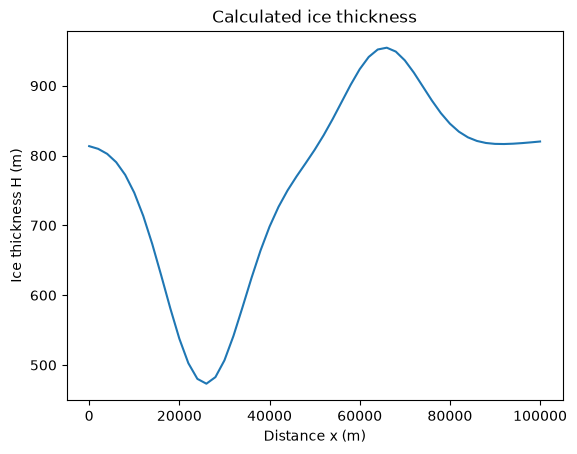

In [13]:
plt.figure()
plt.plot(x, H)
plt.xlabel("Distance x (m)")
plt.ylabel("Ice thickness H (m)")
plt.title("Calculated ice thickness")
plt.show()

In [14]:
#Calculate bedrock

b = h - H

print("Minimum bedrock:", np.min(b))
print("Maximum bedrock:", np.max(b))

Minimum bedrock: -393.0351603536326
Maximum bedrock: 241.5350691211642


In [15]:
print (b)

[   5.99623782    4.10334823    5.50546824   11.54124806   23.57506189
   42.66413828   69.11885064  102.05705924  139.10892242  176.43786208
  209.18091757  232.28180063  241.53506912  234.54753106  211.3133699
  174.2102341   127.41482976   75.92793612   24.51002323  -23.17935689
  -65.05399822 -100.64992975 -130.83810859 -157.34509072 -182.21743851
 -207.32242    -233.93638648 -262.45459725 -292.25937886 -321.78642612
 -348.80904634 -370.90957581 -386.04133041 -393.03516035 -391.9027001
 -383.8441878  -370.96377766 -355.7901466  -340.75496243 -327.77657656
 -318.03992899 -311.98609437 -309.45988618 -309.93268901 -312.72231445
 -317.15943528 -322.68346952 -328.87625396 -335.45416853 -342.24023155
 -349.13208237]


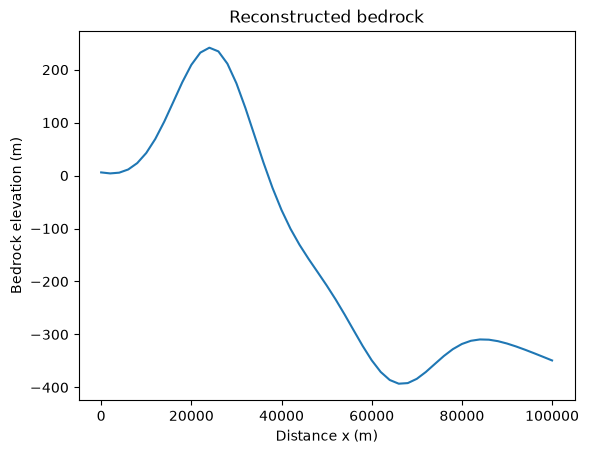

In [16]:
plt.figure()
plt.plot(x, b)
plt.xlabel("Distance x (m)")
plt.ylabel("Bedrock elevation (m)")
plt.title("Reconstructed bedrock")
plt.show()

In [17]:
#Create the two bump shapes

L = 1.e5
angle = 0.2

tan = np.tan(angle * np.pi / 180)


bedbase = -tan * x

bump1 = icemodel.bump(
    1.0, x, 0.5*L/2., L, tan
)

bump2 = icemodel.bump(
    1.0, x, 1.3*L/2., L, tan
)

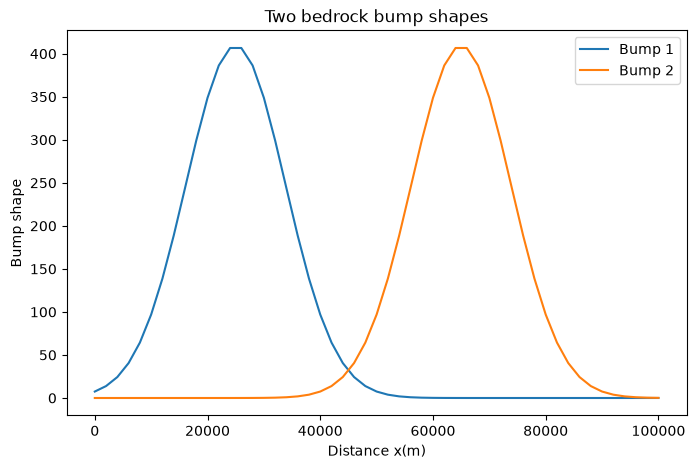

In [18]:
plt.figure(figsize=(8,5))
plt.plot(x, bump1, label="Bump 1")
plt.plot(x, bump2, label="Bump 2")
plt.xlabel("Distance x(m)")
plt.ylabel("Bump shape")
plt.title("Two bedrock bump shapes")
plt.legend()
plt.show()

In [19]:
#find the two amplitudes
y = b - bedbase

X = np.column_stack((bump1, bump2))

amplitudes = np.linalg.lstsq(
    X,
    y,
    rcond=None
)[0]

a1 = amplitudes[0]
a2 = amplitudes[1]

print("a1 =", a1)
print("a2 =", a2)

a1 = 0.8000008241556796
a2 = -0.40000144174567026


In [20]:
bedrock_fit = (bedbase + a1*bump1 + a2*bump2)
print(bedrock_fit)

[   5.99660358    4.10365902    5.50572096   11.54144447   23.5752071
   42.66424095   69.11892264  102.05711437  139.10897416  176.43792081
  209.18098777  232.2818791   241.53514501  234.54758794  211.31338964
  174.2102016   127.41473715   75.92778472   24.50982283  -23.17959084
  -65.05424836 -100.65018038 -130.83834829 -157.34531378 -182.21764497
 -207.32261454 -233.93657631 -262.45478933 -292.25957702 -321.78662865
 -348.80924464 -370.90975463 -386.04146971 -393.03523845 -391.90269733
 -383.84408982 -370.96357764 -355.78984583 -340.75456953 -327.77610563
 -318.03939729 -311.98552022 -309.4592873  -309.9320815  -312.72171244
 -317.15885085 -322.68291302 -328.87573426 -335.45369332 -342.23980754
 -349.13171263]


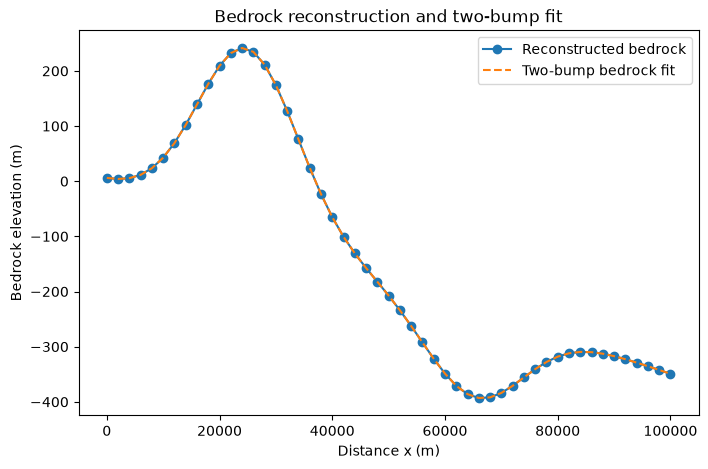

In [21]:
bedrock_fit = bedbase + a1*bump1 + a2*bump2

plt.figure(figsize=(8,5))
plt.plot(x, b,'o-', label="Reconstructed bedrock")
plt.plot(x, bedrock_fit, "--", label="Two-bump bedrock fit")
plt.xlabel("Distance x (m)")
plt.ylabel("Bedrock elevation (m)")
plt.title("Bedrock reconstruction and two-bump fit")
plt.legend()
plt.show()

## Part 2: the 200-year forward simulation.

In [22]:
#Create bedrock

L = 1.e5
angle = 0.2

amplitudes = [a1, a2]

bedrock = icemodel.CreateBedRock(
    angle, amplitudes, x, L
)

In [23]:
#Initial surface thickness

initialthickness = 800

h_forward = icemodel.CreateInitialSurface(
    angle, initialthickness, x, L
)

In [24]:
dx = L / (len(x) - 1)
dt = 0.1

A = 300
rho = 9.138e-19
grav = 9.7692e15
n = 3

In [25]:
time_end = 200

for t in np.arange(0, time_end, dt):

    dhdx_forward, ux_forward, uz_forward = \
        icemodel.VelocityAndSurfaceGradient(
            bedrock,
            h_forward,
            dx,
            rho,
            grav,
            A,
            n
        )

    h_forward = h_forward + dt * (
        -ux_forward * dhdx_forward + uz_forward
    )

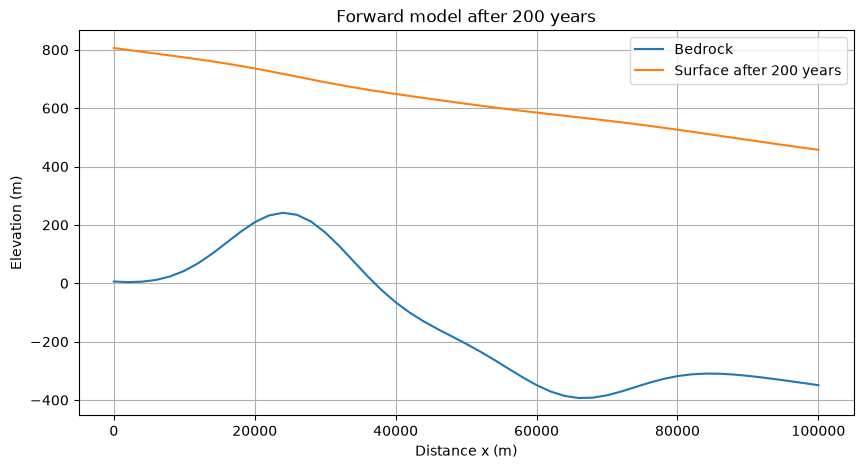

In [26]:
plt.figure(figsize=(10, 5))
plt.plot(x, bedrock, label="Bedrock")
plt.plot(x, h_forward, label="Surface after 200 years")
plt.xlabel("Distance x (m)")
plt.ylabel("Elevation (m)")
plt.title("Forward model after 200 years")
plt.grid()
plt.legend()
plt.show()

## Noise Experiment

In [27]:
#add 2% noise
np.random.seed(42)

h_noisy = h * (1 + 0.02 * np.random.randn(len(h)))

ux_noisy = ux * (1 + 0.02 * np.random.randn(len(ux)))

print("Original h:", h[10])
print("Noisy h:", h_noisy[10])

print("Original ux:", ux[10])
print("Noisy ux:", ux_noisy[10])

Original h: 746.9622084126459
Noisy h: 740.039098347832
Original ux: 1.6200935838320578
Noisy ux: 1.6140778854945803


In [28]:
#Calculate noisy dh/dx
dhdx_noisy = np.zeros(len(h_noisy))

for j in range(1, len(h_noisy)-1):
    dhdx_noisy[j] = (
        h_noisy[j+1] - h_noisy[j-1]
    ) / (2*dx)

heightdiff = h_noisy[0] - h_noisy[-1]

dhdx_noisy[0] = (
    h_noisy[1] - (h_noisy[-2] + heightdiff)
) / (2*dx)

dhdx_noisy[-1] = (
    (h_noisy[1] - heightdiff) - h_noisy[-2]
) / (2*dx)

In [29]:
#Calculate noisy ice thickness
inside = (
    ux_noisy * (n + 1)
    / (-2 * A * (rho * grav)**n * dhdx_noisy**n)
)

H_noisy = np.full(len(h_noisy), np.nan)

valid = inside > 0

H_noisy[valid] = inside[valid] ** (1/(n+1))

print(H_noisy)

[3041.10515442  954.99109325           nan  442.96514826  320.75103584
           nan           nan  293.60045756  547.30144542  585.88996447
  366.51377055  745.3596171   314.15658248  283.70701769 1270.58790816
  759.26813636  953.99187814  625.72818972  338.78428783           nan
           nan  391.3396737   430.71976251  535.71149216           nan
  564.70143678 1058.729288   1798.1913376   565.13370963  907.77190374
           nan 2674.22735356  296.50157618           nan  835.60790576
  617.24871891  585.2856629   425.56329156           nan           nan
  832.00766577  531.73552929  629.48367148  451.76273056  644.59235365
 4882.88462407           nan 1953.18877173  328.10999111  799.33764271
 3065.40674916]


In [30]:
print("Minimum noisy H:",
      np.nanmin(H_noisy))

print("Maximum noisy H:",
      np.nanmax(H_noisy))

Minimum noisy H: 283.70701769032024
Maximum noisy H: 4882.884624072877


In [31]:
#Calculate noisy bedrock
bedrock_noisy = h_noisy - H_noisy

print(bedrock_noisy)

[-2213.46107993  -143.48338469            nan   383.49101701
   471.43570435            nan            nan   493.52606541
   212.4473023    179.93035126   373.5253278    -17.25369975
   411.07747004   397.05015909  -600.52234686   -85.97702544
  -298.44821399    36.96187772   298.61036457            nan
            nan   231.8264287    189.40002467    59.71212239
            nan    37.48546735  -477.23884142 -1203.98842754
    12.43882563  -331.50103427            nan -2082.75325848
   269.22991213            nan  -269.39742106   -78.19247047
   -35.07199253    96.28937785            nan            nan
  -296.51410804    -7.70988795  -114.01617155    56.17330045
  -154.21755461 -4390.48067318            nan -1454.72822272
   157.62660198  -339.43239175 -2591.33138066]


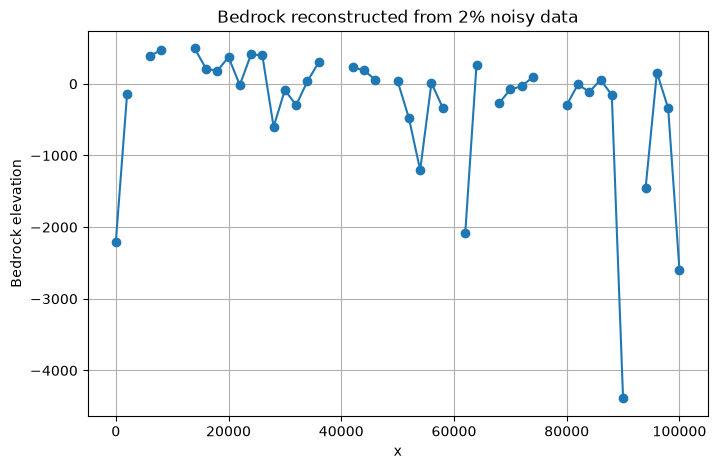

In [32]:
#Plot noisy bedrock
plt.figure(figsize=(8,5))
plt.plot(x, bedrock_noisy,'o-')
plt.xlabel("x")
plt.ylabel("Bedrock elevation")
plt.title("Bedrock reconstructed from 2% noisy data")
plt.grid()
plt.show()    

In [33]:
#Find amplitudes from noisy data

valid = np.isfinite(bedrock_noisy)

y_noisy = (
    bedrock_noisy[valid]
    - bedbase[valid]
)

X_noisy = np.column_stack((
    bump1[valid],
    bump2[valid]
))

amplitudes_noisy = np.linalg.lstsq(
    X_noisy,
    y_noisy,
    rcond=None
)[0]

a1_noisy = amplitudes_noisy[0]
a2_noisy = amplitudes_noisy[1]

print("Original a1 =", a1)
print("Noisy a1 =", a1_noisy)

print("Original a2 =", a2)
print("Noisy a2 =", a2_noisy)

Original a1 = 0.8000008241556796
Noisy a1 = 0.611839352669217
Original a2 = -0.40000144174567026
Noisy a2 = -0.5201058468250969


In [34]:
#percentage changes
change_a1 = (
    abs(a1_noisy - a1) / abs(a1)
) * 100

change_a2 = (
    abs(a2_noisy - a2) / abs(a2)
) * 100

print("Percentage change in a1:", change_a1, "%")
print("Percentage change in a2:", change_a2, "%")

Percentage change in a1: 23.520159705466327 %
Percentage change in a2: 30.025993045242984 %


In [35]:
#Noisy fitted bedrock

bedrock_fit_noisy = (
    bedbase
    + a1_noisy*bump1
    + a2_noisy*bump2
)

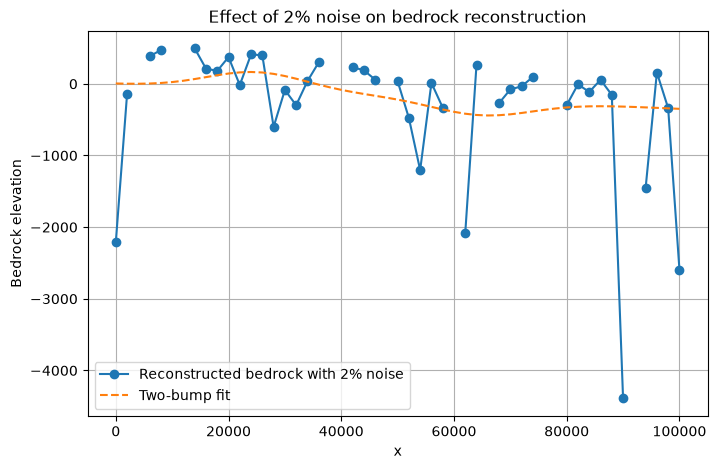

In [36]:
#noisy bedrock and fit plot

plt.figure(figsize=(8,5))
plt.plot(x, bedrock_noisy, 'o-', label="Reconstructed bedrock with 2% noise")
plt.plot(x, bedrock_fit_noisy, '--', label="Two-bump fit")
plt.xlabel("x")
plt.ylabel("Bedrock elevation")
plt.title("Effect of 2% noise on bedrock reconstruction")
plt.legend()
plt.grid()
plt.show()

## Noise Experiment

In [37]:
np.random.seed(42)

noise_h = np.random.randn(len(h))
noise_ux = np.random.randn(len(ux))

In [38]:
noise_levels = [0, 0.01, 0.02, 0.05, 0.10]

In [39]:
noise_levels = [0, 0.01, 0.02, 0.05, 0.10]

results = []

for noise in noise_levels:

    # Add the same noise pattern at different strengths
    h_noisy = h * (1 + noise * noise_h)
    ux_noisy = ux * (1 + noise * noise_ux)

    # Calculate noisy surface gradient
    dhdx_noisy = np.zeros(len(h))

    for j in range(1, len(h)-1):
        dhdx_noisy[j] = (
            h_noisy[j+1] - h_noisy[j-1]
        ) / (2*dx)

    heightdiff = h_noisy[0] - h_noisy[-1]

    dhdx_noisy[0] = (
        h_noisy[1] - (h_noisy[-2] + heightdiff)
    ) / (2*dx)

    dhdx_noisy[-1] = (
        (h_noisy[1] - heightdiff) - h_noisy[-2]
    ) / (2*dx)

    # Calculate ice thickness
    inside = (
        ux_noisy * (n + 1)
        / (-2*A*(rho*grav)**n*dhdx_noisy**n)
    )

    H_noisy = np.full(len(h), np.nan)

    valid = inside > 0

    H_noisy[valid] = inside[valid]**(1/(n+1))

    # Calculate bedrock
    bedrock_noisy = h_noisy - H_noisy

    # Fit two-bump model
    valid = np.isfinite(bedrock_noisy)

    X = np.column_stack([
        bump1[valid],
        bump2[valid]
    ])

    y = bedrock_noisy[valid] - bedbase[valid]

    amplitudes_noisy = np.linalg.lstsq(
        X, y, rcond=None
    )[0]

    a1_noisy = amplitudes_noisy[0]
    a2_noisy = amplitudes_noisy[1]

    results.append([
        noise * 100,
        a1_noisy,
        a2_noisy
    ])

In [40]:
results


[[0, np.float64(0.8000008241556796), np.float64(-0.40000144174567026)],
 [1.0, np.float64(0.19526328371640583), np.float64(-0.4932476299323259)],
 [2.0, np.float64(0.611839352669217), np.float64(-0.5201058468250969)],
 [5.0, np.float64(1.575069174717123), np.float64(0.8293403946091663)],
 [10.0, np.float64(1.6843713878310755), np.float64(1.3866189739271402)]]

In [41]:
results_table = pd.DataFrame(results,columns=["Noise (%)", "a1", "a2"]) 

results_table

,Noise (%),a1,a2
0,0.0,0.800001,-0.400001
1,1.0,0.195263,-0.493248
2,2.0,0.611839,-0.520106
3,5.0,1.575069,0.829340
4,10.0,1.684371,1.386619


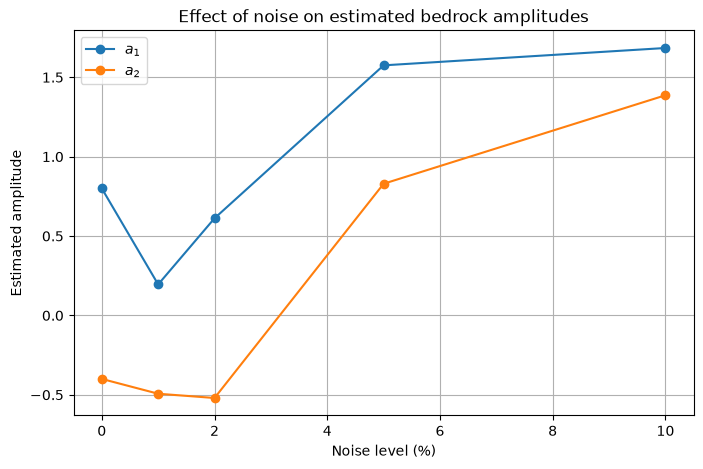

In [42]:
plt.figure(figsize=(8,5))
plt.plot(results_table["Noise (%)"], results_table["a1"],'o-', label="$a_1$")
plt.plot(results_table["Noise (%)"], results_table["a2"], 'o-', label="$a_2$")
plt.xlabel("Noise level (%)")
plt.ylabel("Estimated amplitude")
plt.title("Effect of noise on estimated bedrock amplitudes")
plt.legend()
plt.grid()
plt.show()